In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
df = pd.read_csv('../data/raw/cleaned_retail_sales_data.csv')

In [17]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Category
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,"Seasonal, Party & Stationery"
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Home Decor & Living
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Home Decor & Living
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Home Decor & Living
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Home Decor & Living


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400916 entries, 0 to 400915
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      400916 non-null  int64  
 1   StockCode    400916 non-null  object 
 2   Description  400916 non-null  object 
 3   Quantity     400916 non-null  int64  
 4   InvoiceDate  400916 non-null  object 
 5   Price        400916 non-null  float64
 6   Customer ID  400916 non-null  float64
 7   Country      400916 non-null  object 
 8   Category     400916 non-null  object 
dtypes: float64(2), int64(2), object(5)
memory usage: 27.5+ MB


In [19]:
df.describe()

,Invoice,Quantity,Price,Customer ID
count,400916.000000,400916.000000,400916.000000,400916.000000
mean,514731.380771,13.767418,3.305826,15361.544074
std,14090.603233,97.638385,35.047719,1680.635823
min,489434.000000,1.000000,0.001000,12346.000000
25%,502752.000000,2.000000,1.250000,13985.000000
50%,515192.000000,5.000000,1.950000,15311.000000
75%,527065.500000,12.000000,3.750000,16805.000000
max,538171.000000,19152.000000,10953.500000,18287.000000


In [20]:
df.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country', 'Category'],
      dtype='object')

In [21]:
# plt.figure(figsize=(8,6))

# sns.heatmap(
#     df[['Quantity', 'Price', 'TotalAmount']].corr(),
#     annot=True,
#     cmap='coolwarm',
#     fmt='.2f'
# )

# plt.title('Correlation Heatmap')

# plt.show()

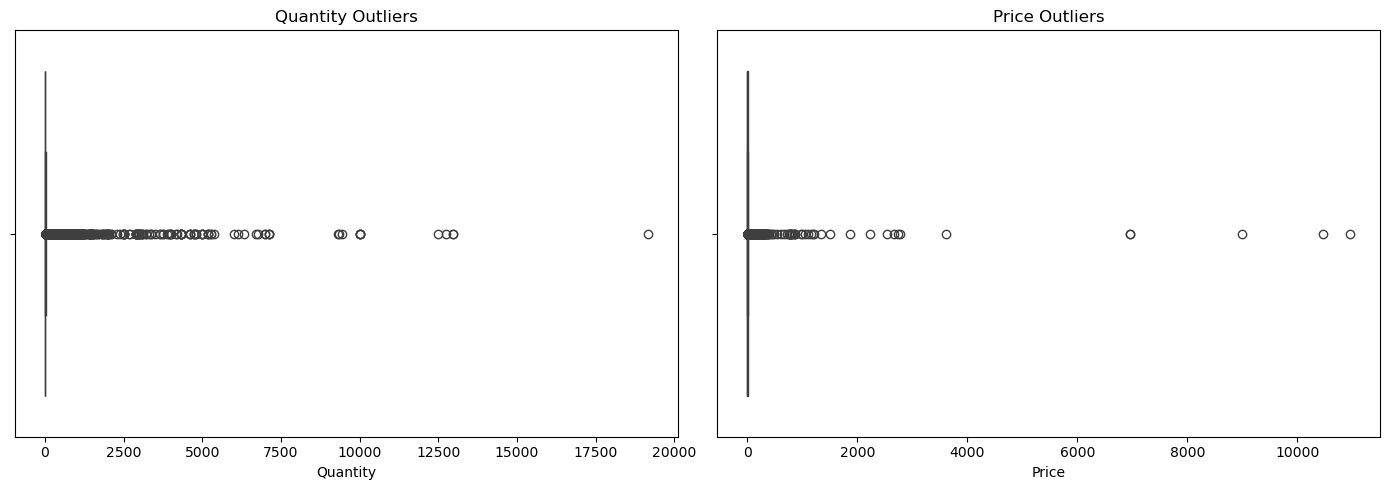

In [22]:
plt.figure(figsize=(14,5))

plt.subplot(1,2,1)
sns.boxplot(x=df['Quantity'])
plt.title('Quantity Outliers')

plt.subplot(1,2,2)
sns.boxplot(x=df['Price'])
plt.title('Price Outliers')

plt.tight_layout()
plt.show()

In [23]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Convert Customer ID to integer
df['Customer ID'] = df['Customer ID'].astype(int)

# Create Total Sales column
df['TotalAmount'] = df['Quantity'] * df['Price']

# Extract date and time information
df['Year'] = df['InvoiceDate'].dt.year
df['Month'] = df['InvoiceDate'].dt.month
df['MonthName'] = df['InvoiceDate'].dt.month_name()
df['Day'] = df['InvoiceDate'].dt.day
df['DayName'] = df['InvoiceDate'].dt.day_name()
df['Hour'] = df['InvoiceDate'].dt.hour

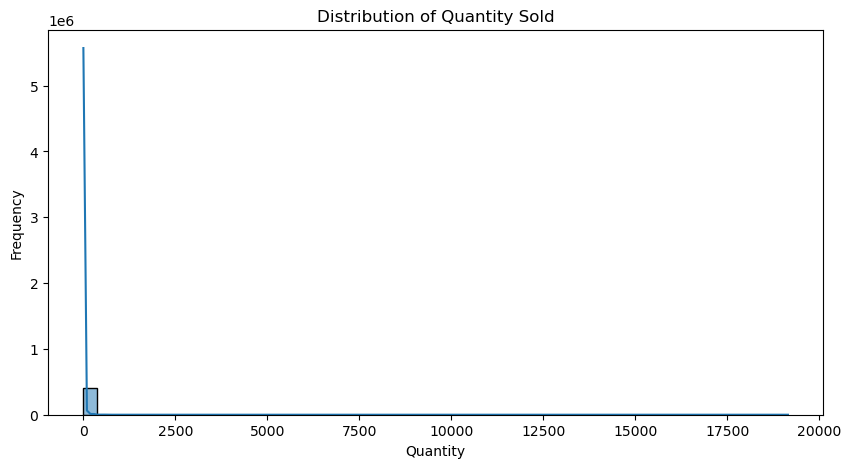

In [24]:
plt.figure(figsize=(10,5))

sns.histplot(df['Quantity'], bins=50, kde=True)

plt.title('Distribution of Quantity Sold')
plt.xlabel('Quantity')
plt.ylabel('Frequency')

plt.show()

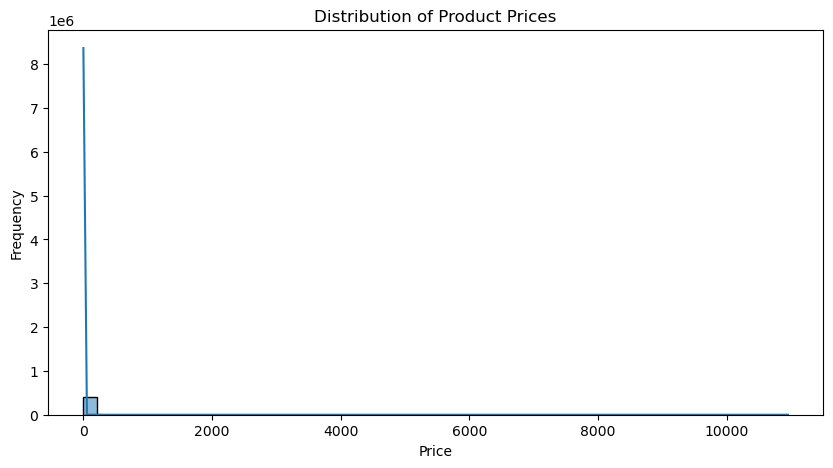

In [25]:
plt.figure(figsize=(10,5))

sns.histplot(df['Price'], bins=50, kde=True)

plt.title('Distribution of Product Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')

plt.show()

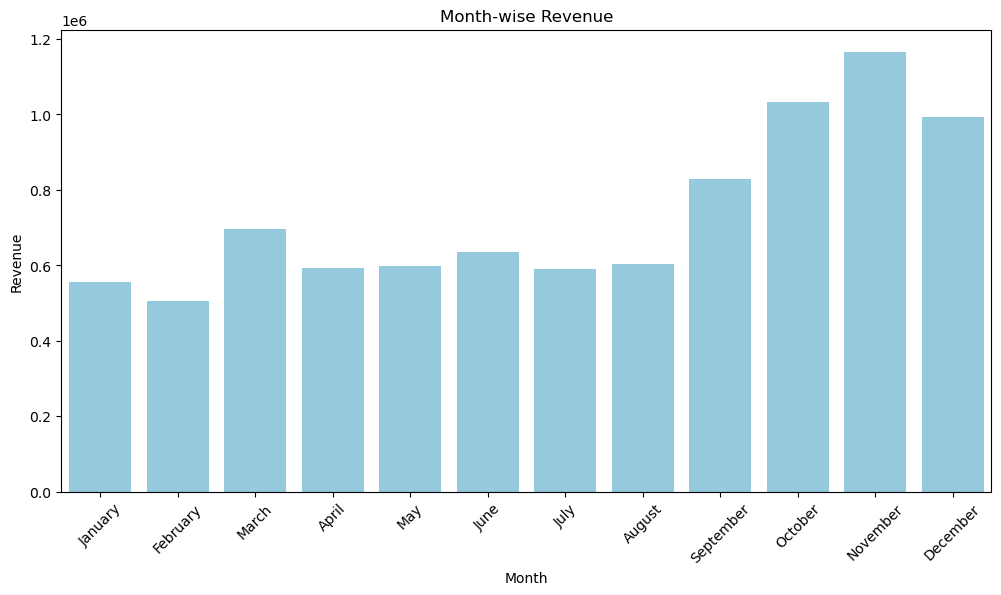

In [26]:
monthly_sales = df.groupby('MonthName')['TotalAmount'].sum()

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_sales = monthly_sales.reindex(month_order)

plt.figure(figsize=(12,6))

sns.barplot(x=monthly_sales.index, y=monthly_sales.values, color='skyblue')

plt.title('Month-wise Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue')

plt.xticks(rotation=45)
plt.show()

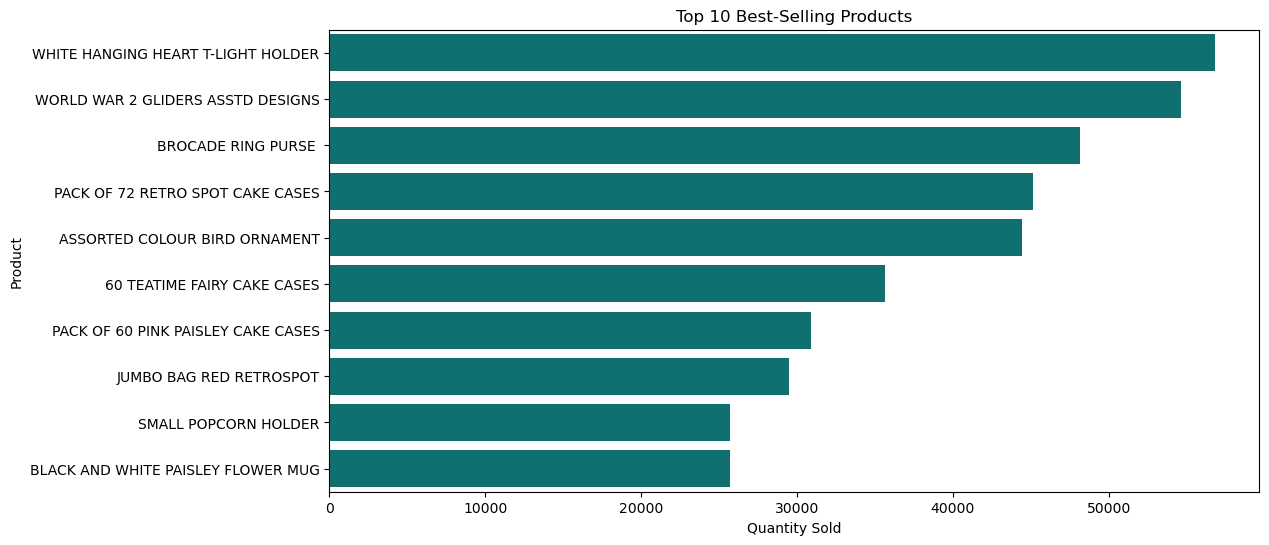

In [27]:
top_products = df.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12,6))

sns.barplot(x=top_products.values, y=top_products.index, color='teal')

plt.title('Top 10 Best-Selling Products')
plt.xlabel('Quantity Sold')
plt.ylabel('Product')

plt.show()

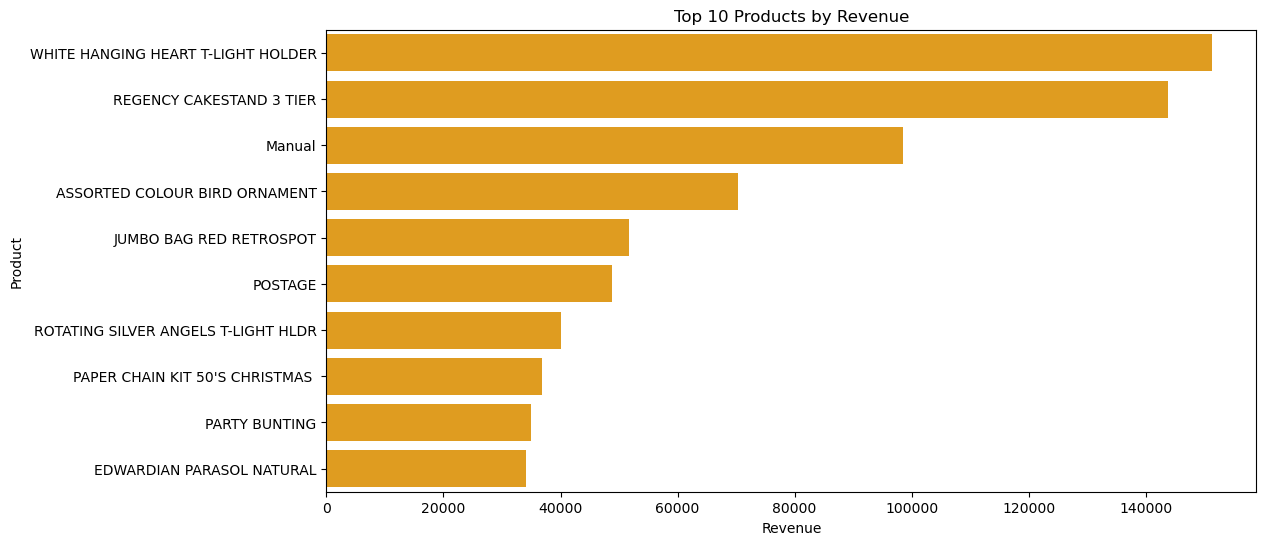

In [28]:
top_revenue = df.groupby('Description')['TotalAmount'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12,6))

sns.barplot(x=top_revenue.values, y=top_revenue.index, color='orange')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product')

plt.show()

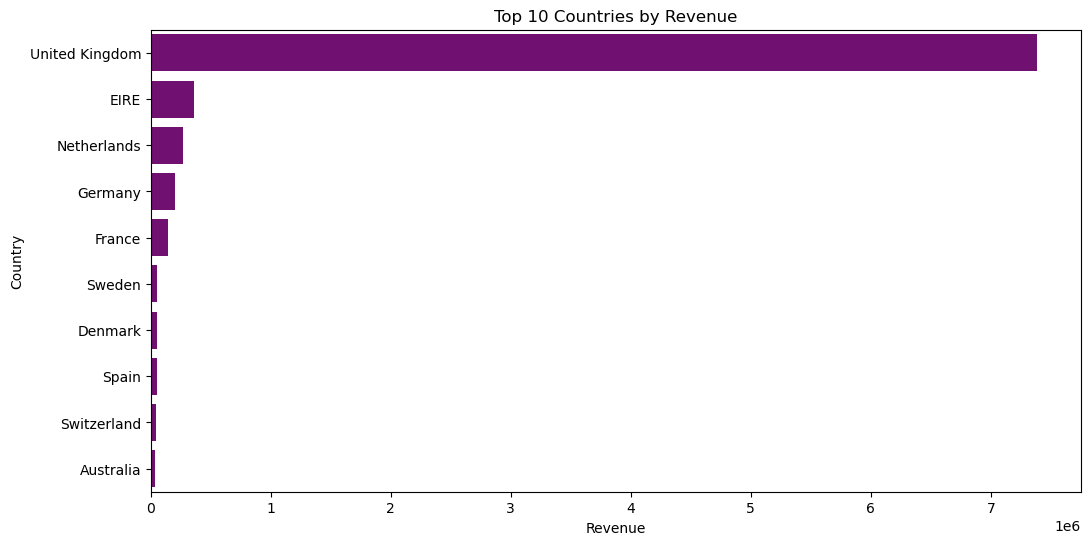

In [29]:
country_sales = df.groupby('Country')['TotalAmount'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12,6))

sns.barplot(x=country_sales.values, y=country_sales.index, color='purple')

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Country')

plt.show()

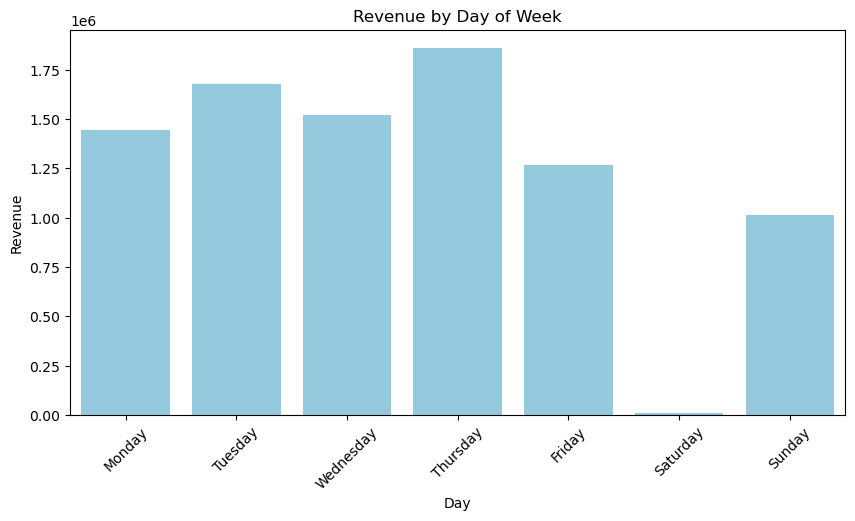

In [30]:
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

day_sales = df.groupby('DayName')['TotalAmount'].sum().reindex(day_order)

plt.figure(figsize=(10,5))

sns.barplot(x=day_sales.index, y=day_sales.values, color='skyblue')

plt.title('Revenue by Day of Week')
plt.xlabel('Day')
plt.ylabel('Revenue')

plt.xticks(rotation=45)
plt.show()

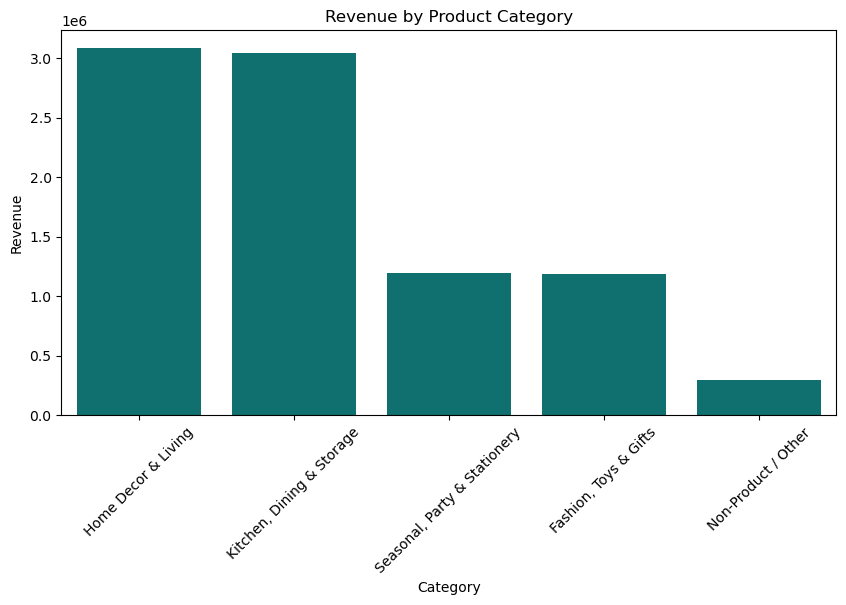

In [31]:
category_sales = df.groupby('Category')['TotalAmount'].sum().sort_values(ascending=False)

plt.figure(figsize=(10,5))

sns.barplot(x=category_sales.index, y=category_sales.values, color='teal')

plt.title('Revenue by Product Category')
plt.xlabel('Category')
plt.ylabel('Revenue')

plt.xticks(rotation=45)
plt.show()